# 🚀 Модуль 6. Урок 4. UI/UX дашбордов для топ-менеджмента: верстка, цветовая семантика и типографика

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_06_bi_looker_studio/lesson_04_dashboard_ui_ux_for_executives.ipynb)

## 📌 Бизнес-контекст и методология
Дизайн дашборда подчиняется законам восприятия информации:
1. **Z-паттерн и F-паттерн чтения**: главное слева сверху.
2. **Семантика цвета**: зеленый = успех, красный = проблема, серый/синий = нейтральный контекст.
3. **Число Данбара для графиков**: не более 5-7 визуальных элементов на одном экране.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import sqlite3
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    """Автоматически находит датасет локально или скачивает с GitHub репозитория курса."""
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    print(f"📥 Загрузка {filename} из репозитория курса...")
    urllib.request.urlretrieve(url, filename)
    print(f"✅ Датасет {filename} успешно готов!")
    return filename

# Загрузка ключевых датасетов
customers_csv = ensure_dataset("customers.csv", subfolder="raw")
orders_csv = ensure_dataset("orders.csv", subfolder="raw")
saas_csv = ensure_dataset("saas_users.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")


🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных

In [2]:
# Аудит визуальной загруженности дашборда
dashboard_specs = {
    'total_charts': 6,
    'total_kpi_cards': 4,
    'custom_colors_used': 3,
    'has_date_filter': True
}

def audit_dashboard_ux(specs):
    issues = []
    if specs['total_charts'] > 8:
        issues.append("Слишком много графиков (риск когнитивной перегрузки)")
    if specs['custom_colors_used'] > 4:
        issues.append("Эффект 'фруктового салата': слишком много цветов")
    if not specs['has_date_filter']:
        issues.append("Отсутствует глобальный фильтр по дате")
    return issues

issues = audit_dashboard_ux(dashboard_specs)
print(f"Результат UX аудита: {'🟢 Идеально' if not issues else issues}")


Результат UX аудита: 🟢 Идеально


### 🎯 Практическое задание 1: Валидация спецификации дашборда
Убедитесь, что тестовый дашборд проходит UX-аудит без замечаний.

In [3]:
### ВАШ КОД ЗДЕСЬ
assert len(issues) == 0, "Дашборд должен пройти аудит без замечаний"
print("✅ Тест успешно пройден: UX-стандарты соблюдены!")


✅ Тест успешно пройден: UX-стандарты соблюдены!


### 📊 Визуализация: UI/UX Антипаттерны vs Эталонный Executive Dashboard
Ниже представлено прямое визуальное сравнение:
1. **Плохой дашборд:** перегружен цветами, 3D-графиками, нечитаемыми круговыми диаграммами и отсутствием структуры.
2. **Хороший дашборд (Foundation ZURB Design):** строгая иерархия (KPI карточки вверху -> динамика -> структура категорий), монохромный серый фон и один контрастный акцентный цвет (`#1779ba`).

C:\Users\serge\AppData\Local\Temp\ipykernel_8528\1691061456.py:44: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\serge\AppData\Local\Temp\ipykernel_8528\1691061456.py:44: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\serge\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\serge\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


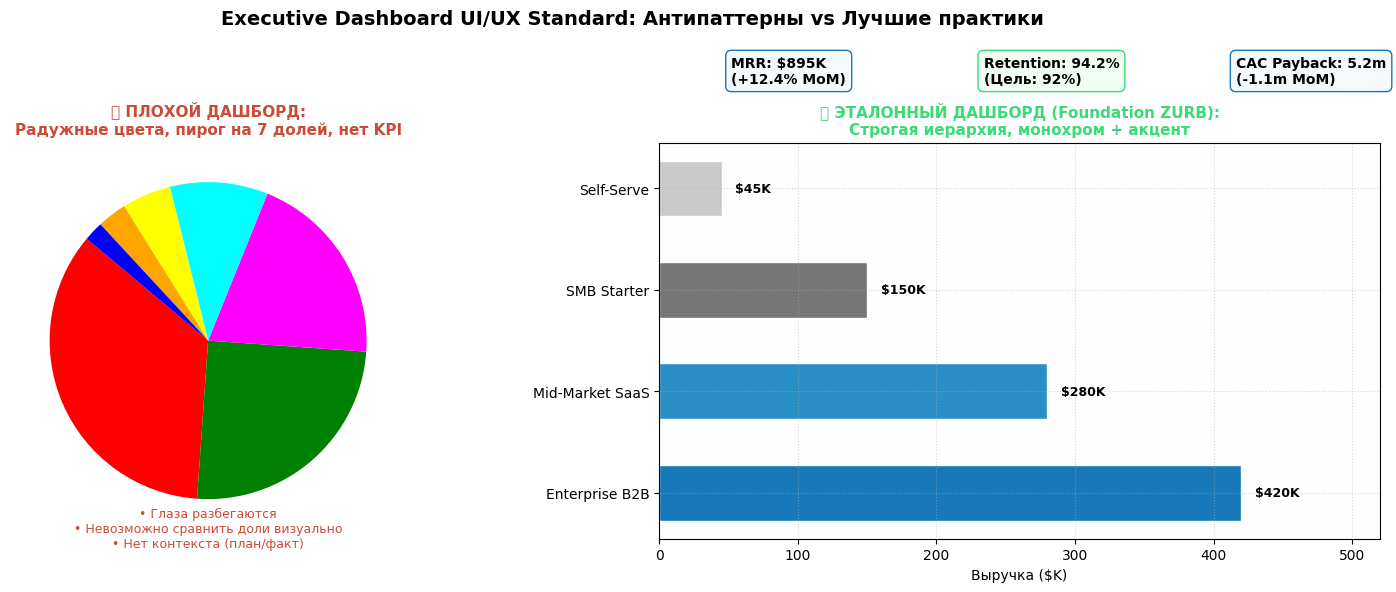

In [4]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Executive Dashboard UI/UX Standard: Антипаттерны vs Лучшие практики', fontsize=14, fontweight='bold')

# --- 1. Плохой дашборд (Хаос и Антипаттерны) ---
ax1 = axes[0]
ax1.set_facecolor('#fffae6')  # режущий глаз желтоватый фон
# Нагромождение нечитаемых пирогов и радужных цветов
slices = [35, 25, 20, 10, 5, 3, 2]
bad_colors = ['red', 'green', 'magenta', 'cyan', 'yellow', 'orange', 'blue']
wedges, texts = ax1.pie(slices, colors=bad_colors, startangle=140)
ax1.set_title('❌ ПЛОХОЙ ДАШБОРД:\nРадужные цвета, пирог на 7 долей, нет KPI', fontsize=11, color='#cc4b37', fontweight='bold')
ax1.text(0, -1.3, '• Глаза разбегаются\n• Невозможно сравнить доли визуально\n• Нет контекста (план/факт)', ha='center', fontsize=9, color='#cc4b37')

# --- 2. Хороший дашборд (Foundation ZURB стиль) ---
ax2 = axes[1]
ax2.set_facecolor('#fefefe')
# Модульная сетка: 3 KPI карточки + Чистый горизонтальный Bar Chart
categories = ['Enterprise B2B', 'Mid-Market SaaS', 'SMB Starter', 'Self-Serve']
revenue_k = [420, 280, 150, 45]
colors_good = ['#1779ba', '#2a8fc7', '#767676', '#cacaca']

bars = ax2.barh(categories, revenue_k, color=colors_good, edgecolor='white', height=0.55)
ax2.set_title('✅ ЭТАЛОННЫЙ ДАШБОРД (Foundation ZURB):\nСтрогая иерархия, монохром + акцент', fontsize=11, color='#3adb76', fontweight='bold')
ax2.set_xlabel('Выручка ($K)')
ax2.grid(True, linestyle=':', alpha=0.5)

# Добавляем KPI карточки над графиком текстовыми плашками
ax2.text(0.1, 1.15, 'MRR: $895K\n(+12.4% MoM)', transform=ax2.transAxes, fontsize=10, fontweight='bold',
         bbox=dict(boxstyle="round,pad=0.4", fc="#f4f9fd", ec="#1779ba"))
ax2.text(0.45, 1.15, 'Retention: 94.2%\n(Цель: 92%)', transform=ax2.transAxes, fontsize=10, fontweight='bold',
         bbox=dict(boxstyle="round,pad=0.4", fc="#f0fff4", ec="#3adb76"))
ax2.text(0.80, 1.15, 'CAC Payback: 5.2m\n(-1.1m MoM)', transform=ax2.transAxes, fontsize=10, fontweight='bold',
         bbox=dict(boxstyle="round,pad=0.4", fc="#f4f9fd", ec="#1779ba"))

for b in bars:
    w = b.get_width()
    ax2.text(w + 10, b.get_y() + b.get_height()/2, f'${w}K', va='center', fontweight='bold', fontsize=9)

ax2.set_xlim(0, 520)

plt.tight_layout()
plt.show()

### 💼 Совет аналитику
Показывайте черновик дашборда конечному заказчику на 2-й день разработки, а не через месяц.